## Plotting Paths and Fonts

Run this cell before the plotting cells.


In [ ]:
from pathlib import Path
import matplotlib.font_manager as fm

NOTEBOOK_DIR = Path("notebooks") if Path("notebooks/paper_figures.ipynb").is_file() else Path(".")
DATA_DIR = NOTEBOOK_DIR / "paper_figures_data"
assert (NOTEBOOK_DIR / "paper_figures.ipynb").is_file(), "Run from the project root or notebooks directory."

REGULAR_FONT = NOTEBOOK_DIR / "Arial.ttf"
BOLD_FONT = NOTEBOOK_DIR / "Arial-Bold.ttf"
fm.fontManager.addfont(str(REGULAR_FONT))
fm.fontManager.addfont(str(BOLD_FONT))


## F2P and Baselines Across Simulated Noise Levels


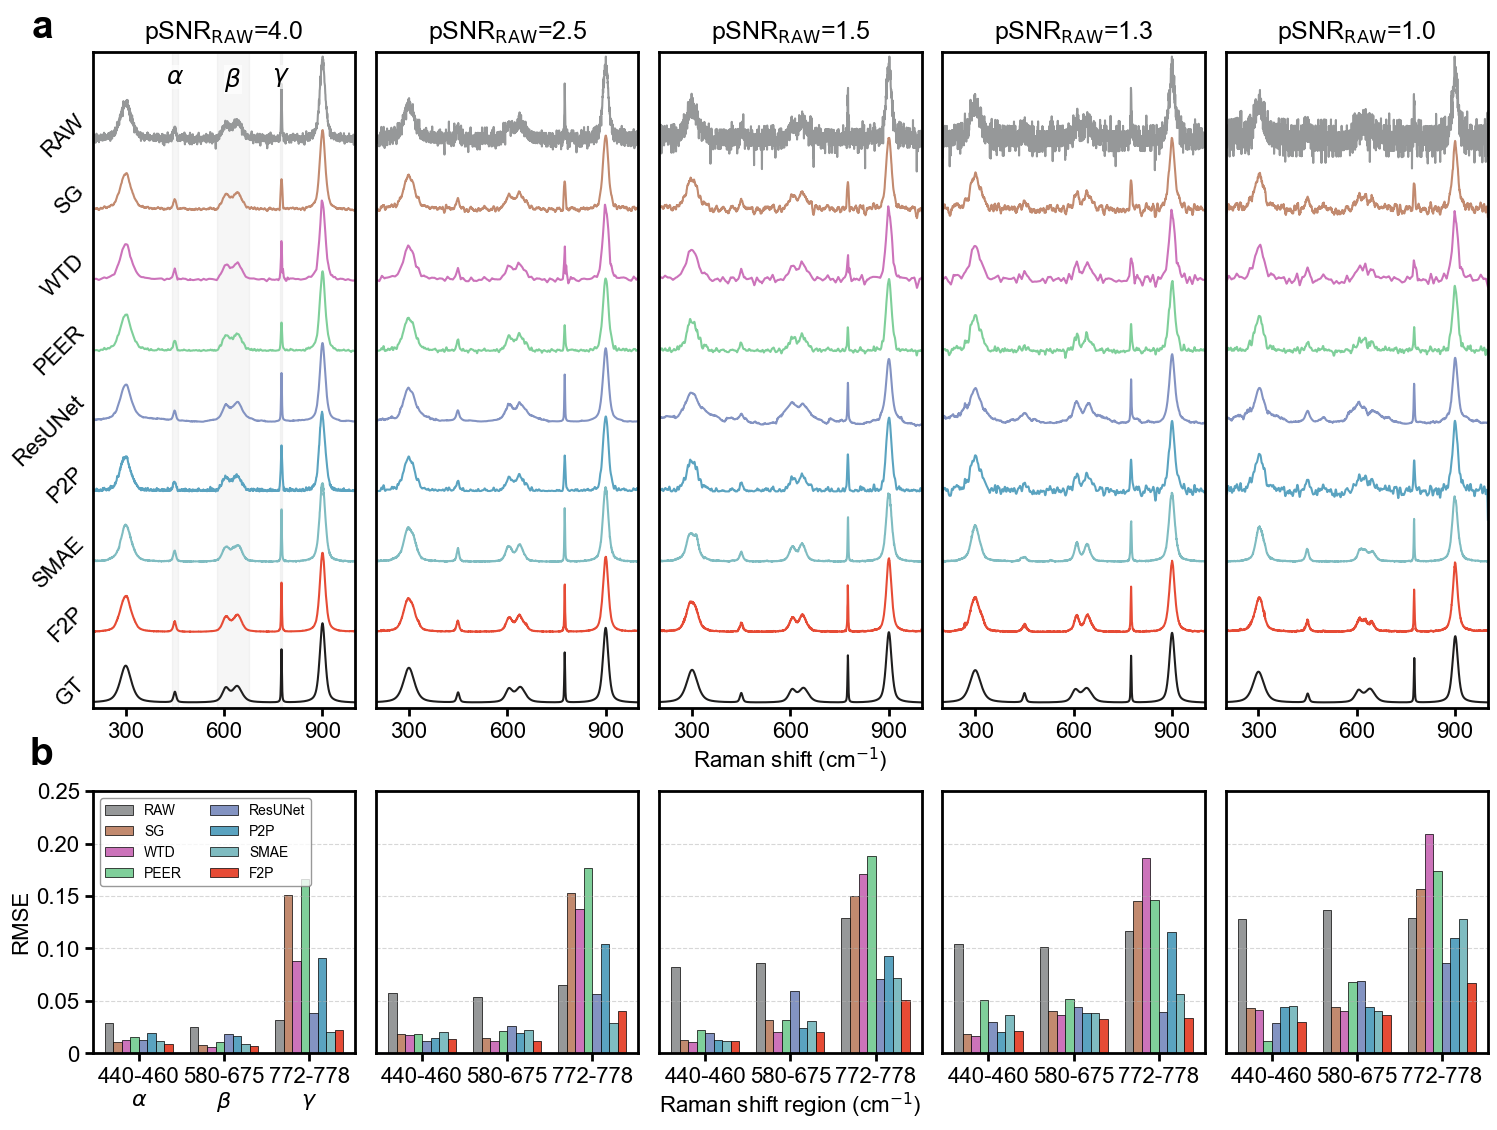

In [32]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib.gridspec as gridspec

# 1. 字体与颜色设置
# 严格参考最新参数
try:
    FONT_PATH = REGULAR_FONT
    font_prop_20 = fm.FontProperties(fname=FONT_PATH, size=18)
    font_prop_16 = fm.FontProperties(fname=FONT_PATH, size=16)
    font_prop_12 = fm.FontProperties(fname=FONT_PATH, size=12)
    font_prop_legend = fm.FontProperties(fname=FONT_PATH, size=10)
except:
    font_prop_20 = fm.FontProperties(size=18)
    font_prop_16 = fm.FontProperties(size=16)
    font_prop_12 = fm.FontProperties(size=12)
    font_prop_legend = fm.FontProperties(size=5)

plt.rcParams.update({'font.size': 16})

COLOR_NOISY = '#969899'
COLOR_GT = '#1F1E1E'

color_map = {
    'SG': "#c28a6f",
    'WTD': "#cc73ba", 
    'PEER': "#7FCF9A", 
    'ResUNet': "#8393C2",
    'P2P': "#5AA3C0",
    'SMAE': "#7fbcc1",
    'F2P': '#E64B35',
}

# ================= 2. 数据准备与路径管理 =================
data_dir = DATA_DIR / "simulated_denoising"
# 确保包含全部五列 SNR
snrs = ["4.0", "2.5", "1.5", "1.3", "1.0"] 
algo_keys = ['SG', 'WTD', 'PEER', 'ResUNet', 'P2P', 'SMAE', 'F2P']

all_labels = ["RAW"] + algo_keys + ["GT"]
colors_line = [COLOR_NOISY] + [color_map[k] for k in algo_keys] + [COLOR_GT]

# 读取 Ground Truth
gt_file = os.path.join(data_dir, "Demo_GT.txt")
gt_data = np.loadtxt(gt_file)
x_axis = gt_data[:, 0]
gt_spec = gt_data[:, 1]

# 柱状图数据：手动确保对应 5 个 SNR
rmse_data = {
    "440-460": {
        "4.0": [0.0294, 0.0111, 0.0125, 0.0159, 0.0127, 0.0194, 0.0120, 0.0090], 
        "2.5": [0.0579, 0.0186, 0.0171, 0.0189, 0.0115, 0.0147, 0.0208, 0.0140],
        "1.5": [0.0828, 0.0132, 0.0106, 0.0221, 0.0190, 0.0124, 0.0121, 0.0117],
        "1.3": [0.1043, 0.0188, 0.0163, 0.0505, 0.0300, 0.0200, 0.0367, 0.0217],
        "1.0": [0.1281, 0.0432, 0.0415, 0.0121, 0.0291, 0.0446, 0.0451, 0.0301],
    },
    "580-675": {
        "4.0": [0.0251, 0.0078, 0.0065, 0.0110, 0.0182, 0.0169, 0.0088, 0.0067],
        "2.5": [0.0536, 0.0151, 0.0116, 0.0218, 0.0266, 0.0193, 0.0222, 0.0119],
        "1.5": [0.0860, 0.0316, 0.0205, 0.0314, 0.0591, 0.0241, 0.0308, 0.0207],
        "1.3": [0.1013, 0.0408, 0.0363, 0.0519, 0.0447, 0.0387, 0.0383, 0.0332],
        "1.0": [0.1362, 0.0445, 0.0403, 0.0679, 0.0688, 0.0442, 0.0407, 0.0370],
    },
    "772-778": {
        "4.0": [0.0319, 0.1509, 0.0885, 0.1661, 0.0384, 0.0906, 0.0209, 0.0227],
        "2.5": [0.0655, 0.1526, 0.1374, 0.1763, 0.0567, 0.1038, 0.0292, 0.0407],
        "1.5": [0.1290, 0.1500, 0.1710, 0.1880, 0.0708, 0.0932, 0.0719, 0.0508],
        "1.3": [0.1166, 0.1453, 0.1858, 0.1464, 0.0399, 0.1156, 0.0562, 0.0339],
        "1.0": [0.1287, 0.1568, 0.2095, 0.1743, 0.0859, 0.1103, 0.1283, 0.0667],
    }
}
regions = ["440-460", "580-675", "772-778"]
region_labels = [r"$\alpha$", r"$\beta$", r"$\gamma$"]
labels_bar = ["RAW"] + algo_keys
colors_bar = [COLOR_NOISY] + [color_map[k] for k in algo_keys]

# ================= 3. 开始绘图 (参考重写逻辑) =================
# 采用大尺寸画布参数
fig = plt.figure(figsize=(18, 13))
# 修改为 5 列，采用 5:2 的比例
gs = fig.add_gridspec(nrows=2, ncols=5, height_ratios=[5, 2])

# --- 第 1 行：(a) 光谱降噪对比矩阵 ---
ax_top = [fig.add_subplot(gs[0, i]) for i in range(5)]

for ax_idx, snr in enumerate(snrs):
    ax = ax_top[ax_idx]
    
    # 动态加载对应 SNR 的文件
    noisy_spec = np.loadtxt(os.path.join(data_dir, f"Demo_SNR{snr}.txt"))[:, 1]
    algo_specs = []
    for k in algo_keys:
        algo_specs.append(np.loadtxt(os.path.join(data_dir, f"Demo_SNR{snr}_{k}.txt"))[:, 1])
        
    lines = [noisy_spec] + algo_specs + [gt_spec]
    
    spec_max = np.max(noisy_spec)
    offset = spec_max * 0.85 # 采用 0.85 偏移量确保间距
    if offset == 0: offset = 1.0 
    
    y_ticks_positions = []
    for i, line in enumerate(lines):
        y_pos = -i * offset
        ax.plot(x_axis, line + y_pos, color=colors_line[i], linewidth=1.5)
        y_ticks_positions.append(y_pos)

    if ax_idx == 0:
        highlight_region = [
            (440, 460),
            (580, 675),
            (772, 778)
        ]
        for (start, end), region_label in zip(highlight_region, region_labels):
            ax.axvspan(start, end, color='gray', alpha=0.07)
            ax.text(
                (start + end) / 2, 0.98, region_label,
                transform=ax.get_xaxis_transform(), fontsize=18,
                ha='center', va='top', zorder=5,
                bbox=dict(facecolor='white', edgecolor='none', alpha=0.7, pad=0.5)
            )
        
    ax.set_ylim(y_ticks_positions[-1]*1.01, spec_max * 1.05)
    ax.set_xlim([200, 1000])
    
    # Y轴刻度处理
    label_shift = offset * 0.3 
    shifted_yticks = [pos + label_shift for pos in y_ticks_positions]
    ax.set_yticks(shifted_yticks)
    
    if ax_idx == 0:
        ax.set_yticklabels(all_labels, fontproperties=font_prop_16, rotation=45)
    else:
        ax.set_yticklabels([])
    ax.tick_params(axis='y', length=0)
    
    ax.set_title(rf"pSNR$_{{\mathrm{{RAW}}}}$={snr}", fontsize=18, pad=10)
    ax.set_xticks([300, 600, 900])
    for label in ax.get_xticklabels():
        label.set_fontproperties(font_prop_16)

# 第一行 X 轴标签居中 (索引 2)
ax_top[2].set_xlabel(r"Raman shift (cm$^{-1}$)", fontproperties=font_prop_16, labelpad=3)

# --- 第 2 行：(b) RMSE柱状图矩阵 ---
num_algos = len(labels_bar)
bar_width = 0.8 / num_algos
ax_bottom = [fig.add_subplot(gs[1, i]) for i in range(5)]

for col_idx, snr in enumerate(snrs):
    ax = ax_bottom[col_idx]
    x = np.arange(len(regions))
    
    for algo_idx, algo_label in enumerate(labels_bar):
        algo_vals = [rmse_data[reg][snr][algo_idx] for reg in regions]
        offset_val = (algo_idx - num_algos/2 + 0.5) * bar_width
        ax.bar(x + offset_val, algo_vals, width=bar_width, label=algo_label, 
               color=colors_bar[algo_idx], edgecolor='black', linewidth=0.5)
        
    ax.set_xticks(x)
    tick_labels = regions
    if col_idx == 0:
        tick_labels = [f"{region}\n{label}" for region, label in zip(regions, region_labels)]
    ax.set_xticklabels(tick_labels, fontproperties=font_prop_16)
    
    # 统一 Y 轴，放宽至 0.25 以适应低 SNR 波动
    ax.set_ylim(0, 0.25)
    ax.set_yticks([0, 0.05, 0.10, 0.15, 0.20, 0.25])
    
    if col_idx == 0:
        ax.set_ylabel("RMSE", fontproperties=font_prop_16)
        ax.set_yticklabels(["0", "0.05", "0.10", "0.15", "0.20", "0.25"], fontproperties=font_prop_16)
    else:
        ax.set_yticklabels([])
        ax.tick_params(axis='y', length=0)
    
    ax.grid(True, axis='y', linestyle="--", alpha=0.5)
    
    # 仅在首个子图展示两列图例
    if col_idx == 0:
        ax.legend(loc='upper left', ncol=2, frameon=True, facecolor='white', edgecolor='gray', prop=font_prop_legend)

# 第二行 X 轴标签居中
ax_bottom[2].set_xlabel(r"Raman shift region (cm$^{-1}$)", fontproperties=font_prop_16, labelpad=3)

# 追加大标签 (a) (b)，参考坐标参数 -0.15
panel_font = fm.FontProperties(fname=BOLD_FONT, weight='bold')
ax_top[0].text(
    -0.15, 1.01, "a", transform=ax_top[0].transAxes,
    fontproperties=panel_font, fontsize=28, va='bottom', ha='right'
)
ax_bottom[0].text(
    -0.15, 1.07, "b", transform=ax_bottom[0].transAxes,
    fontproperties=panel_font, fontsize=28, va='bottom', ha='right'
)

# 严格参考间距参数
plt.subplots_adjust(hspace=0.18, wspace=0.08)
plt.savefig(NOTEBOOK_DIR / "spectra_theo.svg", bbox_inches='tight')
plt.show()

## F2P Denoising Across Raman Instruments


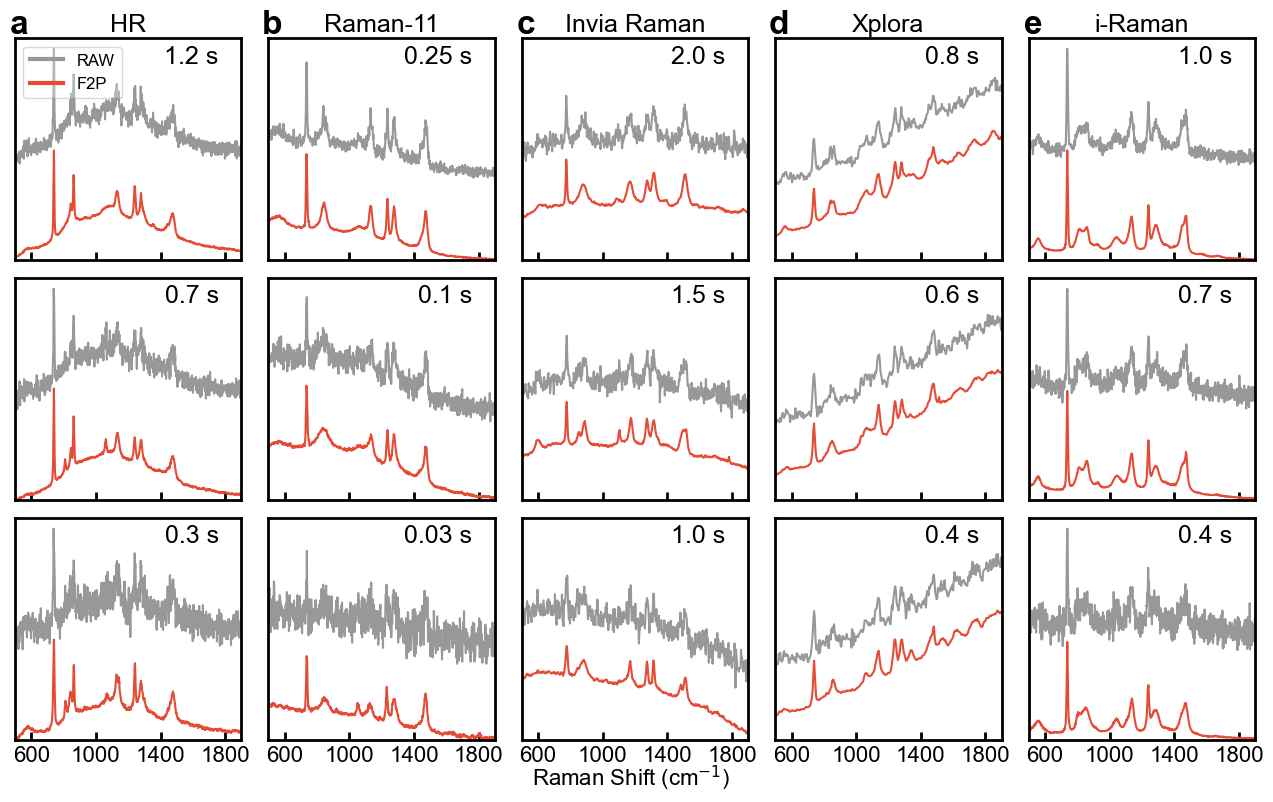

In [33]:
import os
import numpy as np
import matplotlib.font_manager as fm
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
from pathlib import Path

# ================= 1. 全局配置与数据 =================

BASE_PATH = DATA_DIR / 'cross_instrument_spectra'
FONT_PATH = REGULAR_FONT

# 定义仪器顺序和编号
order_list = [
    ('HR',       'a'),
    ('Raman-11',     'b'),
    ('Invia Raman', 'c'),
    ('Xplora',   'd'),
    ('i-Raman',  'e'),
]

INSTRUMENT_CONFIGS = {
    'HR': {
        'times': [0.3, 0.7, 1.2],
        'offset_factor': 0.86,
        'top_margin': 0.05,  # 普通仪器给一点点留白即可
    },
    'Raman-11': {
        'times': [0.03, 0.1, 0.25],
        'offset_factor': 0.66,
        'top_margin': 0.05,
    },
    'Invia Raman': {
        'times': [1.0, 1.5, 2.0],
        'offset_factor': 0.56,
        'top_margin': 0.35,
    },
    'Xplora': {
        'times': [0.4, 0.6, 0.8],
        'offset_factor': 0.36,
        'top_margin': 0.15,
    },
    'i-Raman': {
        'times': [0.4, 0.7, 1.0],
        'offset_factor': 0.86,
        'top_margin': 0.05,
    },
}

METHOD_CONFIG = {
    'Noisy': {'color': '#969899', 'alpha': 1.0, 'label': 'RAW'},
    'F2P':   {'color': '#E64B35', 'alpha': 1.0, 'label': 'F2P'},
}

# 字体设置
fm.fontManager.addfont(str(FONT_PATH))
fm.fontManager.addfont(BOLD_FONT)
font_prop = fm.FontProperties(fname=str(FONT_PATH))
font_name = font_prop.get_name()

plt.rcParams.update({
    'font.family': font_name,
    'font.size': 16,
    'axes.linewidth': 2.0,
    'xtick.major.width': 2.0,
    'ytick.major.width': 2.0,
    'xtick.major.size': 6.0,
    'ytick.major.size': 6.0,
    'axes.unicode_minus': False,
    'savefig.format': 'svg',
    'figure.dpi': 100
})

def load_spectrum_txt(data_path):
    data = np.loadtxt(data_path)
    return data[:, 0], data[:, 1]

# ================= 2. 主程序执行 (重构为 3行 N列) =================

num_cols = len(order_list) # 动态计算列数 (仪器数)
num_rows = 3               # 固定为 3 个时间点

# 根据列数动态调整图片宽度，保持每个子图的宽高比适中
fig_width = 3 * num_cols + 1 
fig_height = 9
fig = plt.figure(figsize=(fig_width, fig_height))

# 创建 3行 x N列 的全局网格
# hspace/wspace 控制子图间的纵向/横向间距
gs = gridspec.GridSpec(num_rows, num_cols, hspace=0.08, wspace=0.12)

# 创建一个 ax 矩阵方便索引 [row, col]
axs_matrix = [[fig.add_subplot(gs[i, j]) for j in range(num_cols)] for i in range(num_rows)]

# 外层循环：遍历列（仪器）
for col_idx, (inst_name, label_char) in enumerate(order_list):
    cfg = INSTRUMENT_CONFIGS[inst_name]
    # 时间倒序：最上面放最长时间（信号最强），最下面放最短时间
    times_reversed = cfg['times'][::-1]
    offset_factor = cfg['offset_factor']
    top_margin_factor = cfg['top_margin']  # 获取该仪器的顶部留白因子
    
    # 内层循环：遍历行（时间）
    for row_idx, time_val in enumerate(times_reversed):
        ax = axs_matrix[row_idx][col_idx]
        
        # 构造基础路径
        base_file_path = f"{BASE_PATH}/{inst_name}/{time_val}s"
        
        # --- 1. 绘制 RAW ---
        try:
            waves, ins_raw = load_spectrum_txt(f"{base_file_path}.txt")
            ax.plot(waves, ins_raw, 
                    color=METHOD_CONFIG['Noisy']['color'], 
                    linewidth=1.5,
                    label=METHOD_CONFIG['Noisy']['label']) 
            
            # --- 2. 绘制 F2P (带偏移) ---
            ins_range = ins_raw.max() - ins_raw.min()
            current_offset = -ins_range * offset_factor
            
            _, ins_f2p = load_spectrum_txt(f"{base_file_path}_F2P.txt")
            ax.plot(waves, ins_f2p + current_offset, 
                    color=METHOD_CONFIG['F2P']['color'], 
                    linewidth=1.5,
                    label=METHOD_CONFIG['F2P']['label'])
            
            # ================= 3. 动态设置 Y 轴范围 =================
            # 计算数据边界
            y_data_top = ins_raw.max()
            y_data_bottom = (ins_f2p + current_offset).min()
            y_span = y_data_top - y_data_bottom
            
            # 计算上方留白量
            margin_val = y_span * top_margin_factor
            
            # 设置 Y 轴：底部紧贴数据最小值，顶部留出空间
            ax.set_ylim(y_data_bottom, y_data_top + margin_val)
            # ======================================================
        except FileNotFoundError as e:
            ax.text(0.5, 0.5, "Data Not Found", ha='center', va='center', transform=ax.transAxes)
            # continue

        # ================== 装饰逻辑 ==================
        
        # 1. 仪器标题 (仅在第一行显示)
        if row_idx == 0:
            ax.set_title(inst_name, fontsize=18, pad=5)
            
        # 2. (a)/(b) 编号 (仅在第一行显示)
        if row_idx == 0:
             ax.text(0.06, 1.13, label_char, transform=ax.transAxes,
                    fontsize=24, fontweight='bold', va='top', ha='right')

        # 3. 图例 (仅在第一行第一列显示)
        if row_idx == 0 and col_idx == 0:
            leg = ax.legend(loc='upper left',
                            bbox_to_anchor=(0.0, 1.00), # 放在左上角内部上方
                            ncol=1,
                            frameon=True,
                            framealpha=0.3,
                            fontsize=12,
                            # handlelength=1.2,
                            edgecolor='gray',)
            for line in leg.get_lines():
                line.set_linewidth(3.0)

        # 4. 时间标签 (每个子图右上角)
        ax.text(0.90, 0.97, f'{time_val} s', transform=ax.transAxes, 
                ha='right', va='top', fontsize=18, fontweight='medium')
        
        # 5. 坐标轴设置
        ax.set_xlim(500, 1900)
        ax.set_xticks([600, 1000, 1400, 1800])
        ax.set_yticks([]) # 隐藏所有 Y 轴刻度
        ax.tick_params(axis='x', direction='in', top=False, labelsize=16)

        # 关键：如果不是最后一行，隐藏 X 轴刻度标签，实现共享 X 轴效果
        if row_idx < num_rows - 1:
            ax.set_xticklabels([])

# 全局 X 轴标签 (放在底部中央)
fig.text(0.51, 0.05, r'Raman Shift (cm$^{-1}$)', ha='center', fontsize=16)
# 留出底部空间给全局标签
plt.subplots_adjust(bottom=0.1)

# bbox_inches='tight' 可能会裁掉全局标签，这里手动控制边界
plt.savefig((NOTEBOOK_DIR / 'GENERATION.svg') ,bbox_inches='tight') 
plt.show()


## F2P and Baselines on Experimental Raman Spectra


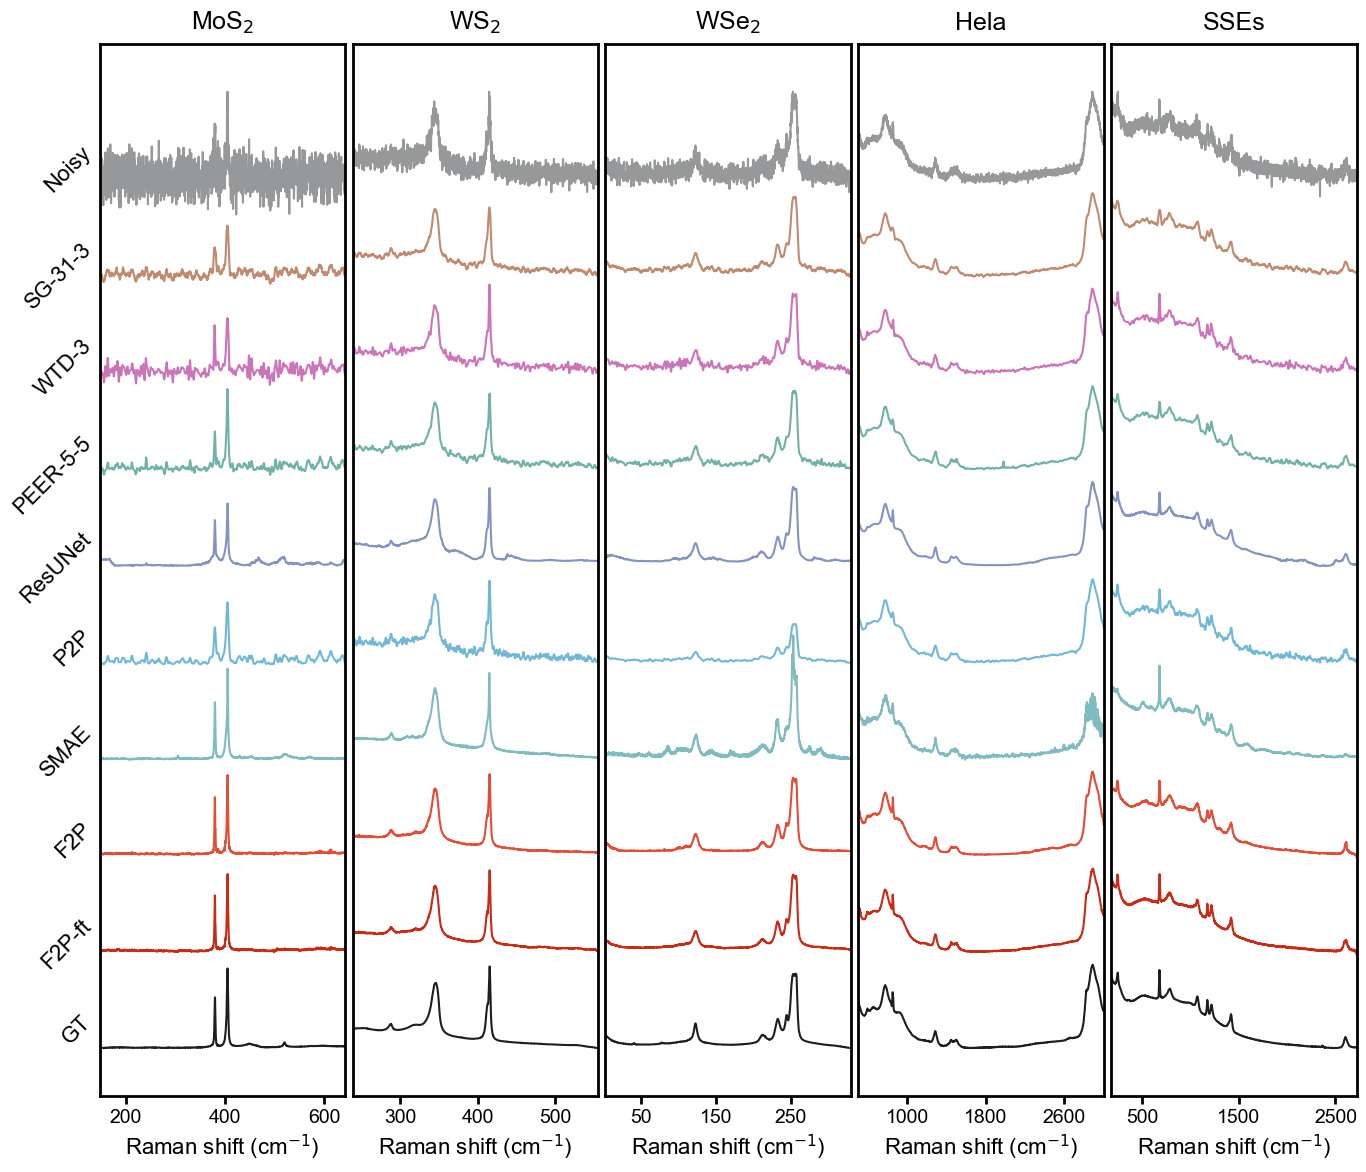

In [34]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# ================= 1. 字体与颜色设置 =================
FONT_PATH = REGULAR_FONT
font_prop_20 = fm.FontProperties(fname=FONT_PATH, size=18)
font_prop_16 = fm.FontProperties(fname=FONT_PATH, size=16)
font_prop_12 = fm.FontProperties(fname=FONT_PATH, size=14)
plt.rcParams.update({'font.size': 16})

COLOR_NOISY = '#969899'
COLOR_GT = '#1F1E1E'

color_map = {
    'sg313': "#c28a6f", 
    'wtd3': "#cc73ba", 
    'peer 5 5': "#71B2A8", 
    'resunet': "#8393C2",
    'p2p': "#70B9D6",
    'smae raw ps1': "#7fbcc1",
    'f2p rpe': '#E64B35',
    'f2p rpe ft': '#CB2A15'
}

algo_keys = ['sg313', 'wtd3', 'peer 5 5', 'resunet','p2p', 'smae raw ps1', 'f2p rpe', 'f2p rpe ft']
display_labels = ['SG-31-3', 'WTD-3', 'PEER-5-5', 'ResUNet', 'P2P', 'SMAE', 'F2P', 'F2P-ft']
all_labels = ['Noisy'] + display_labels + ['GT']

samples = ['MoS2', 'WS2', 'WSe2', 'HeLa', 'SSEs']
spectra = [
    np.loadtxt(DATA_DIR / 'experimental_benchmark' / f'{sample}.txt')
    for sample in samples
]
final_noisy = [data[:, 1] for data in spectra]
final_gt = [data[:, -1] for data in spectra]
algo_data_extracted = {
    key: [data[:, column + 2] for data in spectra]
    for column, key in enumerate(algo_keys)
}

# ================= 4. 绘图 =================
ranges = [(148, 642), (238.424, 555.45), (2, 331), (500, 3000), (177, 2718)]
specific_ticks = [
    [200, 400, 600],
    [300, 400, 500],
    [50, 150, 250],
    [1000, 1800, 2600],
    [500, 1500, 2500]
]
source_labels = [r'MoS$_2$', r'WS$_2$', r'WSe$_2$', 'Hela', 'SSEs']

fig, axes = plt.subplots(1, 5, figsize=(14, 12))

for i in range(5):
    ax = axes[i]
    x_min, x_max = ranges[i]
    x_axis = spectra[i][:, 0]
    
    # 动态组装 lines
    lines = [final_noisy[i]]
    for k in algo_keys:
        spec_data = algo_data_extracted[k][i]
        if k == 'p2p' and i in [2]:
            spec_data = spec_data * 0.5
        lines.append(spec_data)
    lines.append(final_gt[i])

    colors = [COLOR_NOISY] + [color_map[k] for k in algo_keys] + [COLOR_GT]
    
    offset = np.max(final_noisy[i]) * 1.1
    if offset == 0: offset = 1.0 
    
    y_ticks_positions = []
    for j, line in enumerate(lines):
        y_pos = -j * offset
        ax.plot(x_axis, line + y_pos, color=colors[j], linewidth=1.5)
        y_ticks_positions.append(y_pos)
        
    label_shift = offset * 0.3
    shifted_yticks = [pos + label_shift for pos in y_ticks_positions]
    
    ax.set_yticks(shifted_yticks)
    if i == 0:
        ax.set_yticklabels(all_labels, fontproperties=font_prop_16, rotation=45)
    else:
        ax.set_yticklabels([])
    ax.tick_params(axis='y', length=0)
    
    ax.set_xticks(specific_ticks[i])
    ax.set_xticklabels(specific_ticks[i], fontproperties=font_prop_12)
    ax.set_xlabel(r"Raman shift (cm$^{-1}$)", fontproperties=font_prop_16)
    ax.set_title(source_labels[i], fontproperties=font_prop_20, pad=10)
    ax.set_xlim(x_min, x_max)

plt.tight_layout()
plt.subplots_adjust(wspace=0.03) 
plt.savefig(NOTEBOOK_DIR / 'spectra_exps.svg', bbox_inches='tight')
plt.show()

## F2P Masking and SMAE Patch Size Ablations


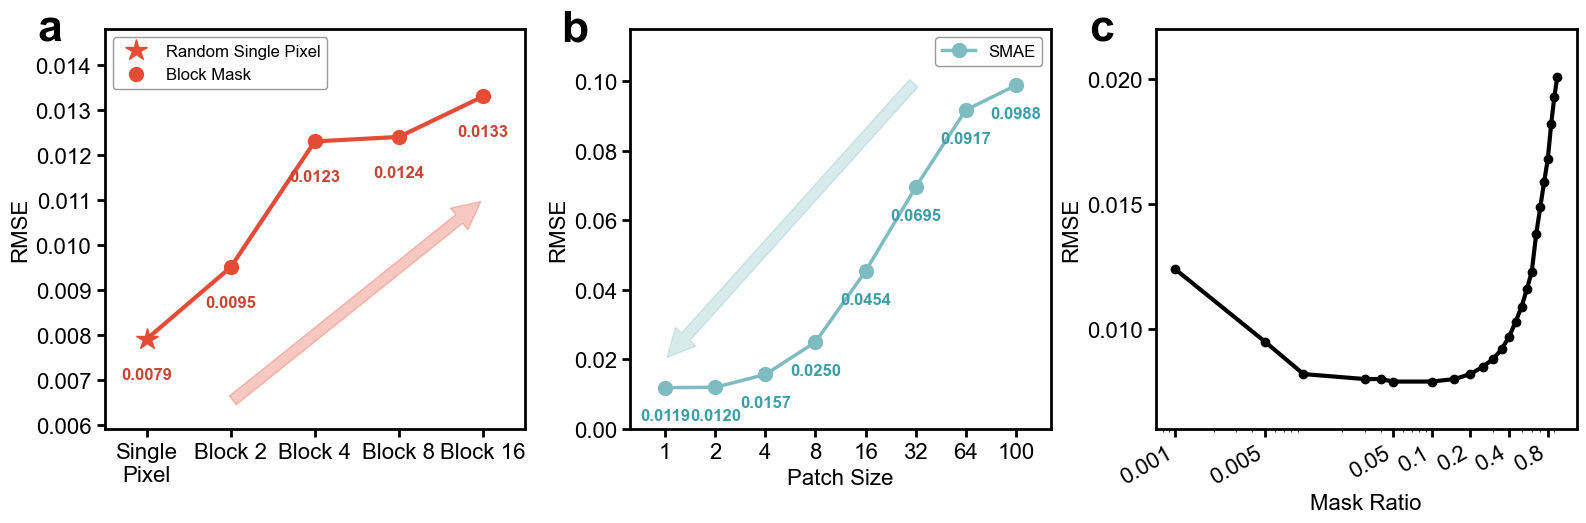

In [35]:
import os
import numpy as np
import matplotlib.font_manager as fm
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path

FONT_PATH = REGULAR_FONT

try:
    if os.path.exists(FONT_PATH):
        fm.fontManager.addfont(str(FONT_PATH))
        font_name = fm.FontProperties(fname=str(FONT_PATH)).get_name()
    else:
        font_name = 'sans-serif'

    plt.rcParams.update({
        'font.family': font_name,
        'font.size': 16,
        'axes.linewidth': 2.0,
        'axes.edgecolor': 'black',
        'xtick.color': 'black',
        'ytick.color': 'black',
        'xtick.major.width': 2.0,
        'ytick.major.width': 2.0,
        'xtick.major.size': 6.0,
        'ytick.major.size': 6.0,
        'axes.unicode_minus': False,
        'savefig.format': 'svg',
        'figure.dpi': 100
    })
except Exception as e:
    print(f"Font loading error: {e}")

mask_strategies = ['Single\nPixel', 'Block 2', 'Block 4', 'Block 8', 'Block 16']
rmse_mask = [0.0079, 0.0095, 0.0123, 0.0124, 0.0133]

ps_time_labels = ['1', '2', '4', '8', '16', '32', '64', '100']

smae_time = [3.4452, 1.2465, 0.5708, 0.3655, 0.2800, 0.2780, 0.2773, 0.2727]

ps_smae_rmse = ['1', '2', '4', '8', '16', '32', '64', '100']
smae_rmse = [0.0119, 0.0120, 0.0157, 0.0250, 0.0454, 0.0695, 0.0917, 0.0988]

fig = plt.figure(figsize=(16, 5))
gs = gridspec.GridSpec(1, 3, wspace=0.25)

x_label_fontsize = 16


ax_a = fig.add_subplot(gs[0])
x_pos = np.arange(len(mask_strategies))

ax_a.plot(x_pos, rmse_mask, linestyle='-', color='#E64B35', linewidth=3, zorder=1, alpha=1)

ax_a.plot(x_pos[0], rmse_mask[0], marker='*', linestyle='', color='#E64B35',
          markersize=16, zorder=2, label='Random Single Pixel')

ax_a.plot(x_pos[1:], rmse_mask[1:], marker='o', linestyle='', color="#E64B35",
          markersize=10, zorder=2, label='Block Mask')

ax_a.set_xticks(x_pos)
ax_a.set_xticklabels(mask_strategies, fontsize=x_label_fontsize)
ax_a.set_ylabel('RMSE')

ax_a.set_ylim(min(rmse_mask) - 0.002, max(rmse_mask) + 0.0015)

for i, (x, y) in enumerate(zip(x_pos, rmse_mask)):

    color = '#C74534' if i == 0 else "#C74534"

    ax_a.annotate(f'{y:.4f}', xy=(x, y), xytext=(0, -20), textcoords='offset points',
                  ha='center', va='top', fontsize=12, color=color, weight='bold')

ax_a.grid(False)

ax_a.legend(loc='upper left', ncol=1, frameon=True, edgecolor='gray', fontsize=12)
panel_font = fm.FontProperties(fname=BOLD_FONT, weight='bold')
ax_a.text(
    -0.1, 1.05, 'a', transform=ax_a.transAxes,
    fontproperties=panel_font, fontsize=32, fontweight='bold',
    va='top', ha='right'
)
ax_a.set_xlim(x_pos[0] - 0.5, x_pos[-1] + 0.5)

arrow_a = mpatches.FancyArrowPatch(
    (1, 0.0065), (4, 0.011),
    arrowstyle='simple,head_width=20,head_length=20,tail_width=8',
    color='#E64B35', zorder=3, alpha=0.3
)
ax_a.add_patch(arrow_a)


ax_b = fig.add_subplot(gs[1])

ax_b.plot(
    ps_smae_rmse, smae_rmse, marker='o', markersize=10,
    linestyle='-', linewidth=2.5, color='#7fbcc1', label='SMAE', alpha=1
)

ax_b.set_xlabel('Patch Size', fontsize=x_label_fontsize)
ax_b.set_ylabel('RMSE')
ax_b.tick_params(axis='x', labelsize=x_label_fontsize)
ax_b.set_ylim(0, 0.115)
ax_b.margins(x=0.1)

ax_b.grid(False)
ax_b.legend(loc='upper right', ncol=1, frameon=True, edgecolor='gray', fontsize=12)
ax_b.text(
    -0.1, 1.05, 'b', transform=ax_b.transAxes,
    fontproperties=panel_font, fontsize=32, fontweight='bold',
    va='top', ha='right'
)

for x, y in zip(ps_smae_rmse, smae_rmse):

    ax_b.annotate(f'{y:.4f}', xy=(x, y), xytext=(0, -15), textcoords='offset points',
                  ha='center', va='top', fontsize=12, color='#3d9da5', weight='bold')

arrow_b = mpatches.FancyArrowPatch(
    (5, 0.10), (0, 0.02),
    arrowstyle='simple,head_width=20,head_length=20,tail_width=8',
    color='#7fbcc1', zorder=3, alpha=0.3
)
ax_b.add_patch(arrow_b)


ax_c = fig.add_subplot(gs[2])

mr_values = np.array([
    0.0010, 0.0050, 0.0100, 0.0300, 0.0400, 0.0500, 0.1000, 0.1500,
    0.2000, 0.2500, 0.3000, 0.3500, 0.4000, 0.4500, 0.5000, 0.5500,
    0.6000, 0.6500, 0.7000, 0.7500, 0.8000, 0.8500, 0.9000, 0.9500
])

rmse_values_mr = np.array([
    0.0124, 0.0095, 0.0082, 0.0080, 0.0080, 0.0079, 0.0079, 0.0080,
    0.0082, 0.0085, 0.0088, 0.0092, 0.0097, 0.0103, 0.0109, 0.0116,
    0.0123, 0.0138, 0.0149, 0.0159, 0.0168, 0.0182, 0.0193, 0.0201
])

ax_c.plot(
    mr_values,
    rmse_values_mr,
    marker='o',
    linestyle='-',
    color='black',
    linewidth=3,
    markersize=6
)

ax_c.set_xscale('log')
ax_c.set_xlabel('Mask Ratio', fontsize=x_label_fontsize)
ax_c.set_ylabel('RMSE')

ax_c.set_ylim(0.006, 0.022)
ax_c.set_yticks([0.01, 0.015, 0.02])

custom_ticks = [0.001, 0.005, 0.05, 0.1, 0.2, 0.4, 0.8]
ax_c.set_xticks(custom_ticks)
ax_c.set_xticklabels(
    [f'{tick:.3f}'.rstrip('0').rstrip('.') for tick in custom_ticks],
    rotation=30,
    ha='right',
    fontsize=x_label_fontsize
)

ax_c.grid(False)

ax_c.text(
    -0.1, 1.05, 'c',
    transform=ax_c.transAxes,
    fontproperties=panel_font,
    fontsize=32,
    fontweight='bold',
    va='top',
    ha='right'
)


fig.subplots_adjust(left=0.06, right=0.98, top=0.92, bottom=0.12)
plt.savefig(NOTEBOOK_DIR / 'mask_anal.svg', bbox_inches='tight')
plt.show()

## F2P Training With and Without Masking


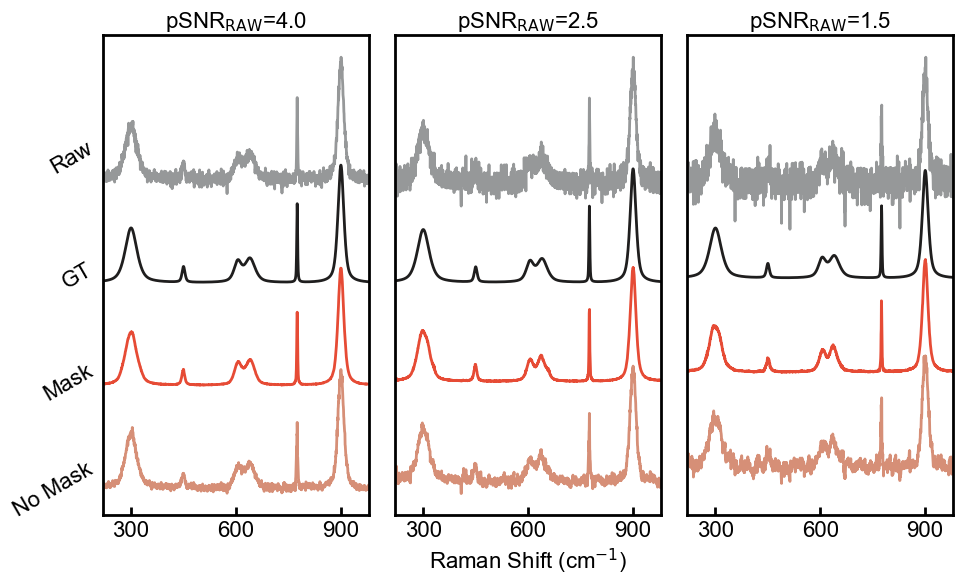

In [36]:
import os
import numpy as np
import matplotlib.font_manager as fm
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
from pathlib import Path

def load_spectrum_txt(data_path):
    waves = np.loadtxt(data_path)[:, 0]
    spec = np.loadtxt(data_path)[:, 1]
    return waves, spec

FONT_PATH = REGULAR_FONT
fm.fontManager.addfont(str(FONT_PATH))
font_prop = fm.FontProperties(fname=str(FONT_PATH))
font_name = font_prop.get_name()

plt.rcParams.update({
    'font.family': font_name,
    'font.size': 16,              # 全局字号
    'font.weight': 'normal',      # 保持清秀，不加粗
    'axes.linewidth': 2.0,        # 边框粗细
    'xtick.major.width': 2.0,     # 刻度线粗细
    'ytick.major.width': 2.0,
    'xtick.major.size': 6.0,      # 刻度线长度
    'ytick.major.size': 6.0,
    'axes.unicode_minus': False,  # 解决负号显示
    'savefig.format': 'svg',
    'figure.dpi': 100
})

CONFIG = {
    'RAW':   {'color': '#969899', 'alpha': 1.0, 'label': 'Raw'},
    'GT':   {'color': '#1F1E1E', 'alpha': 1.0, 'label': 'GT'},
    'F2P':   {'color': '#E64B35', 'alpha': 1.0, 'label': 'Mask'},     # 对应 Demo_SNR{snr}_F2P.txt
    'mr0.0': {'color': '#D68F77', 'alpha': 1.0, 'label': 'No Mask'},  # 对应 Demo_SNR{snr}_mr0.0.txt
}

# ==========================================
# 2. 路径与数据准备
# ==========================================
base_dir = DATA_DIR
paths = {
    'GT和Noisy': base_dir / 'simulated_reference_spectra',  # 假设 GT 和 Noisy 在此
    'denoised': base_dir / 'masking_ablation_spectra',  # 假设去噪结果在此
}

# 加载 Ground Truth (作为基准)
gt_path = paths['GT和Noisy'] / 'Demo_GT.txt'
waves, spec_gt = load_spectrum_txt(gt_path)

# 计算全局 Y 轴偏移量
max_range = np.max(spec_gt) - np.min(spec_gt)
global_gap = max_range * 0.88 # 调整间距倍率，防止重叠

SNR_VALUES = ["4.0", "2.5", "1.5"]  # 列顺序

# ==========================================
# 3. 绘图流程 (扁平化 + GridSpec)
# ==========================================

# 创建画布
fig = plt.figure(figsize=(10, 6))
gs = gridspec.GridSpec(1, 3, figure=fig, wspace=0.1)

# --- 外层循环：遍历列 (SNR) ---
for col_idx, snr in enumerate(SNR_VALUES):
    ax = fig.add_subplot(gs[0, col_idx])
    
    # 设置子图标题 (SNR)
    ax.set_title(rf"pSNR$_{{\mathrm{{RAW}}}}$={snr}", fontsize=16, fontweight='normal')
    
    # 预加载该 SNR 下的 Noisy 数据 (Raw)
    noisy_path = paths['GT和Noisy'] / f'Demo_SNR{snr}.txt'
    res_noisy = load_spectrum_txt(noisy_path)
    if res_noisy is None:
        ax.axis('off')
        continue
    _, spec_noisy = res_noisy

    # --- 内层循环：遍历行 (CONFIG中的方法，从上往下堆叠) ---
    for row_idx, (method_key, style) in enumerate(CONFIG.items()):
        
        # 1. 确定当前要画的数据
        current_spec = None
        
        if method_key == 'GT':
            current_spec = spec_gt
        elif method_key == 'RAW':
            current_spec = spec_noisy
        else:
            # 构建去噪文件路径
            f_path = paths['denoised'] / f'Demo_SNR{snr}_{method_key}.txt'
            res = load_spectrum_txt(f_path)
            if res is not None:
                current_spec = res[1]
            else:
                continue

        # 2. 计算垂直偏移 (向下排布)
        offset = -row_idx * global_gap
        
        # 3. 绘制曲线
        ax.plot(waves, current_spec + offset, 
                lw=2, 
                color=style['color'], 
                alpha=style['alpha'])
        
        # 4. 处理左侧 Y 轴标签 (仅在第一列绘制)
        if col_idx == 0:
            # 在曲线左侧添加文本标签
            # x位置取 waves[0] 左侧一点，y位置取该曲线起始点 + 偏移
            label_x = waves[0]
            label_y = current_spec[0] + offset*1.1
            
            ax.text(label_x, label_y, style['label'], 
                    fontsize=16, 
                    rotation=30,
                    ha='right',
                    va='bottom')

    # --- 子图坐标轴修饰 ---
    ax.set_xticks([300, 600, 900])
    ax.set_xlim(220, 980)
    ax.tick_params(axis='x', direction='in', labelsize=16, top=False)
    
    # 隐藏所有 Y 轴刻度 (因为已经有了左侧的 Text 标签)
    ax.set_yticks([])
    # 仅中间图显示 X 轴 Label (可选)
    if col_idx == 1:
        ax.set_xlabel(r"Raman Shift (cm$^{-1}$)", fontsize=16)

plt.subplots_adjust(left=0.1, right=0.95, top=0.9, bottom=0.1)
fig.savefig(NOTEBOOK_DIR / 'w_o_mask.svg', format='svg', bbox_inches='tight')
plt.show()